In [ ]:

from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

X, y = make_moons(
    n_samples=100,
    noise=0.1,
    random_state=42
)

print(X.shape)
print(y.shape)
print(X[:5])
print(y[:5])


(100, 2)
(100,)
[[ 1.58202308 -0.44581483]
 [ 0.0660451   0.4392075 ]
 [ 0.73663111 -0.39896339]
 [-1.05692838  0.2424558 ]
 [-0.80216162  0.20271838]]
[1 1 1 0 0]


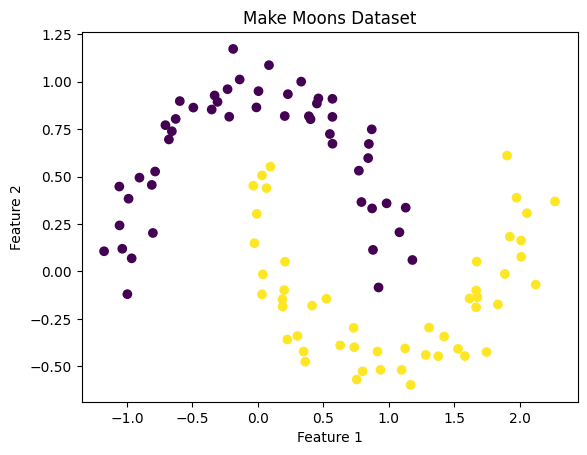

In [ ]:

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Make Moons Dataset")
plt.show()


In [ ]:


inputs = X.tolist()

# Convert class labels 0 and 1 into -1 and +1 for tanh
targets = [2 * int(label) - 1 for label in y]

print(inputs[0],inputs[3])
print(targets[0],targets[3])



[1.582023079145042, -0.4458148298633392] [-1.0569283813519594, 0.24245580185881363]
1 -1


In [ ]:

from engine import Value
from nn import MLP

nn = MLP(2, [8, 8, 1])

print("Number of parameters:", len(nn.parameters()))


Number of parameters: 105


In [ ]:

learning_rate = 0.05
epochs = 1000
loss_history = []

for epoch in range(epochs):
    # 1. Forward pass
    predictions = [nn(x)[0] for x in inputs]

    # 2. Calculate total squared error
    loss = sum(
        (prediction - target) ** 2
        for prediction, target in zip(predictions, targets)
    ) / len(inputs)

    # 3. Reset parameter gradients
    for p in nn.parameters():
        p.grad = 0.0

    # 4. Backpropagation
    loss.backward()

    # 5. Update parameters
    for p in nn.parameters():
        p.data -= learning_rate * p.grad

    loss_history.append(loss.data)

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Loss = {loss.data:.4f}")


Epoch 0: Loss = 2.6125
Epoch 100: Loss = 0.3005
Epoch 200: Loss = 0.2096
Epoch 300: Loss = 0.1392
Epoch 400: Loss = 0.0921
Epoch 500: Loss = 0.0626
Epoch 600: Loss = 0.0443
Epoch 700: Loss = 0.0327
Epoch 800: Loss = 0.0252
Epoch 900: Loss = 0.0200


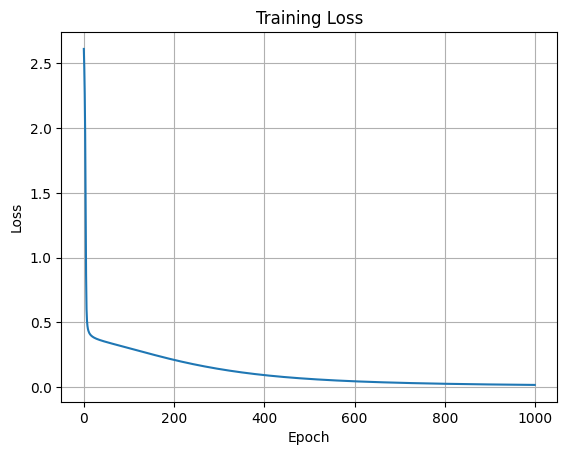

In [ ]:
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

In [ ]:
correct = 0

for x, target in zip(inputs, targets):
    prediction = nn(x)[0].data
    predicted_class = 1 if prediction >= 0 else -1

    if predicted_class == target:
        correct += 1

print(f"Accuracy: {correct / len(inputs) * 100:.2f}%")

Accuracy: 100.00%


Learning rate = 0.001: Final loss = 0.4091
Learning rate = 0.01: Final loss = 0.2450
Learning rate = 0.05: Final loss = 0.0144
Learning rate = 0.1: Final loss = 0.0040


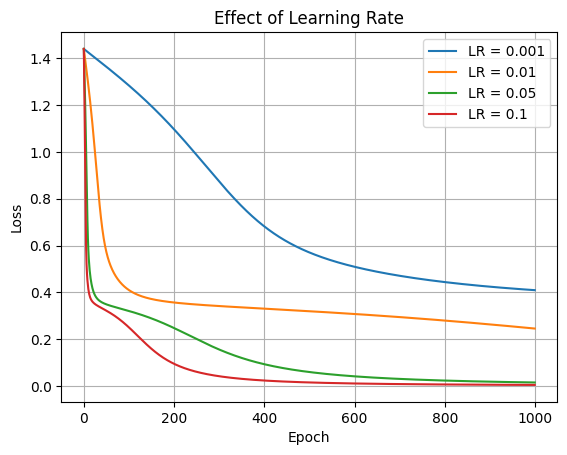

In [ ]:
#experimenting with learning rates
import random
import matplotlib.pyplot as plt

learning_rates = [0.001, 0.01, 0.05, 0.1]
results = {}

for lr in learning_rates:
    random.seed(42)
    model = MLP(2, [8, 8, 1])
    losses = []

    for epoch in range(1000):
        predictions = [model(x)[0] for x in inputs]

        loss = sum(
            (pred - target) ** 2
            for pred, target in zip(predictions, targets)
        ) / len(inputs)

        for p in model.parameters():
            p.grad = 0.0

        loss.backward()

        for p in model.parameters():
            p.data -= lr * p.grad

        losses.append(loss.data)

    results[lr] = losses
    print(f"Learning rate = {lr}: Final loss = {losses[-1]:.4f}")

for lr, losses in results.items():
    plt.plot(losses, label=f"LR = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Learning Rate")
plt.legend()
plt.grid(True)
plt.show()

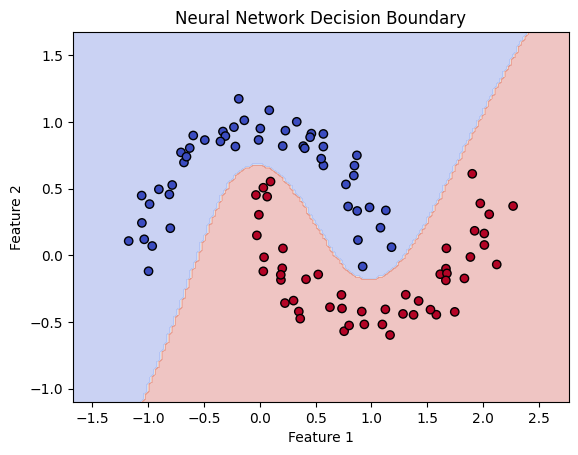

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Create a grid covering the dataset
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 150),
    np.linspace(y_min, y_max, 150)
)

# Predict the class at every point in the grid
grid_points = np.c_[xx.ravel(), yy.ravel()]

predictions = [
    1 if nn(point.tolist())[0].data >= 0 else 0
    for point in grid_points
]

Z = np.array(predictions).reshape(xx.shape)

# Plot the decision boundary and original data
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="black")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Neural Network Decision Boundary")
plt.show()

Epoch 0: Loss = 0.4972
Epoch 100: Loss = 0.0083
Epoch 200: Loss = 0.0019
Epoch 300: Loss = 0.0011
Epoch 400: Loss = 0.0007
Epoch 500: Loss = 0.0005
Epoch 600: Loss = 0.0004
Epoch 700: Loss = 0.0003
Epoch 800: Loss = 0.0003
Epoch 900: Loss = 0.0002


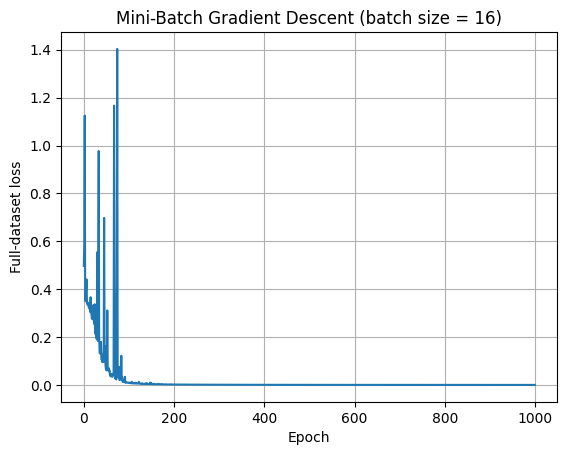

In [ ]:
import random
import matplotlib.pyplot as plt

random.seed(42)

model = MLP(2, [8, 8, 1])

learning_rate = 0.1
epochs = 1000
batch_size = 16

loss_history = []

for epoch in range(epochs):

    # Shuffle the training examples each epoch
    indices = list(range(len(inputs)))
    random.shuffle(indices)

    for start in range(0, len(inputs), batch_size):

        # Get the indices for this batch
        batch_indices = indices[start:start + batch_size]

        # Calculate predictions and loss for this batch
        predictions = [
            model(inputs[i])[0]
            for i in batch_indices
        ]

        batch_loss = sum(
            (pred - targets[i]) ** 2
            for pred, i in zip(predictions, batch_indices)
        ) / len(batch_indices)

        # Reset parameter gradients
        for p in model.parameters():
            p.grad = 0.0

        # Backpropagation
        batch_loss.backward()

        # Update parameters
        for p in model.parameters():
            p.data -= learning_rate * p.grad

    # Measure loss across ALL examples after the epoch
    all_predictions = [model(x)[0] for x in inputs]

    full_loss = sum(
        (pred - target) ** 2
        for pred, target in zip(all_predictions, targets)
    ) / len(inputs)

    loss_history.append(full_loss.data)

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Loss = {full_loss.data:.4f}")

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Full-dataset loss")
plt.title("Mini-Batch Gradient Descent (batch size = 16)")
plt.grid(True)
plt.show()

In [ ]:
# testing on unseen examples
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(
    n_samples=300,
    noise=0.1,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X_train.tolist()
X_test = X_test.tolist()

y_train = [2 * int(label) - 1 for label in y_train]
y_test = [2 * int(label) - 1 for label in y_test]

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 240
Testing examples: 60


In [ ]:
import random

random.seed(42)
model = MLP(2, [8, 8, 1])

learning_rate = 0.05
epochs = 1000

for epoch in range(epochs):
    predictions = [model(x)[0] for x in X_train]

    loss = sum(
        (pred - target) ** 2
        for pred, target in zip(predictions, y_train)
    ) / len(X_train)

    for p in model.parameters():
        p.grad = 0.0

    loss.backward()

    for p in model.parameters():
        p.data -= learning_rate * p.grad

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Loss = {loss.data:.4f}")

Epoch 0: Loss = 1.4057
Epoch 100: Loss = 0.2628
Epoch 200: Loss = 0.2043
Epoch 300: Loss = 0.1334
Epoch 400: Loss = 0.0814
Epoch 500: Loss = 0.0525
Epoch 600: Loss = 0.0366
Epoch 700: Loss = 0.0272
Epoch 800: Loss = 0.0211
Epoch 900: Loss = 0.0170


In [ ]:
def calculate_accuracy(model, X_data, y_data):
    correct = 0

    for x, target in zip(X_data, y_data):
        output = model(x)[0].data
        predicted_class = 1 if output >= 0 else -1

        if predicted_class == target:
            correct += 1

    return 100 * correct / len(y_data)


train_accuracy = calculate_accuracy(model, X_train, y_train)
test_accuracy = calculate_accuracy(model, X_test, y_test)

print(f"Training accuracy: {train_accuracy:.2f}%")
print(f"Test accuracy: {test_accuracy:.2f}%")

Training accuracy: 100.00%
Test accuracy: 100.00%


In [ ]:
import random
import time
import matplotlib.pyplot as plt

architectures = {
    "2 hidden units": [2, 1],
    "4 hidden units": [4, 1],
    "8-8 baseline": [8, 8, 1],
    "16-16 wider": [16, 16, 1],
    "16-16-16 deeper": [16, 16, 16, 1]
}

def accuracy(model, X_data, y_data):
    correct = 0
    for x, target in zip(X_data, y_data):
        output = model(x)[0].data
        predicted = 1 if output >= 0 else -1
        if predicted == target:
            correct += 1
    return 100 * correct / len(y_data)

results = {}

for name, architecture in architectures.items():
    random.seed(42)
    model = MLP(2, architecture)

    start_time = time.time()

    for epoch in range(1000):
        predictions = [model(x)[0] for x in X_train]

        loss = sum(
            (pred - target) ** 2
            for pred, target in zip(predictions, y_train)
        ) / len(X_train)

        for p in model.parameters():
            p.grad = 0.0

        loss.backward()

        for p in model.parameters():
            p.data -= 0.05 * p.grad

    train_acc = accuracy(model, X_train, y_train)
    test_acc = accuracy(model, X_test, y_test)

    results[name] = {
        "train": train_acc,
        "test": test_acc,
        "time": time.time() - start_time
    }

    print(
        f"{name}: "
        f"Train = {train_acc:.2f}%, "
        f"Test = {test_acc:.2f}%, "
        f"Time = {results[name]['time']:.1f}s"
    )

2 hidden units: Train = 89.17%, Test = 80.00%, Time = 78.4s
4 hidden units: Train = 96.25%, Test = 88.33%, Time = 144.5s
8-8 baseline: Train = 100.00%, Test = 100.00%, Time = 946.1s
16-16 wider: Train = 100.00%, Test = 100.00%, Time = 3410.7s
